# End-to-End ETL & Academic Performance Pipeline
## Capstone Project: Education & Student Academic Analytics
**Author:** Prajjwal Gyawali  
**Dataset Source:** [Kaggle Student Dropout & Performance Dataset](https://www.kaggle.com/datasets/muhammadkhubaibahmad/student-performance-and-clustering-dataset)  
**Repository:** [student-performance-analysis](https://github.com/PrajjwalGyawali/student-performance-analysis.git)  

---
### Architecture Overview
$$\text{Raw Data (Kaggle)} \longrightarrow \text{Extract} \longrightarrow \text{EDA \& Quality Audit} \longrightarrow \text{Clean \& Transform} \longrightarrow \text{Normalize (3 Entities)} \longrightarrow \text{SQLite DB} \longrightarrow \text{SQL Reporting}$$

### 1. Environment Configuration & Library Imports

In [1]:
import os
import sys
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

# Configure visual styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 120
print('Environment configured successfully with Pandas, SQLAlchemy, Matplotlib, and Seaborn!')

Environment configured successfully with Pandas, SQLAlchemy, Matplotlib, and Seaborn!


### Phase 1: Data Acquisition & Ingestion
Preserving raw data and loading into Pandas DataFrame.

In [2]:
raw_data_path = os.path.join('..', 'data', 'raw', 'student_dropout_behavior_raw.csv')
df_raw = pd.read_csv(raw_data_path)

print(f'Raw Dataset Dimensions: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns')
print('\nFirst 5 Sample Records:')
display_head = df_raw.head(5)
print(display_head[['student_id', 'name', 'age', 'gender', 'previous_gpa', 'midterm_marks', 'final_marks']])

Raw Dataset Dimensions: 300 rows x 16 columns

First 5 Sample Records:
   student_id              name  age  gender  previous_gpa  midterm_marks  \
0           1  Kristina Vaughan   19    Male          2.57           30.0   
1           2    Rodney Daniels   21    Male          2.40           25.4   
2           3         Jose Nash   19  Female          2.99           14.4   
3           4     Nicole Martin   21    Male          1.68           17.7   
4           5      Shelby Smith   21  Female          2.53           23.8   

   final_marks  
0         36.5  
1         33.0  
2         24.8  
3         41.0  
4         31.0  


### Phase 2: Exploratory Data Analysis & Data Quality Audit
Inspecting data types, uniqueness, missing values, duplicates, text casing, and distribution shapes.

In [3]:
print('--- 2.1 Column Data Types & Cardinality ---')
schema_df = pd.DataFrame({
    'Data Type': df_raw.dtypes.astype(str),
    'Unique Values': df_raw.nunique(),
    'Missing Values': df_raw.isnull().sum()
})
print(schema_df)

--- 2.1 Column Data Types & Cardinality ---
                      Data Type  Unique Values  Missing Values
student_id                int64            300               0
name                        str            297               0
age                       int64              8               0
gender                      str              2               0
quiz1_marks             float64             63               0
quiz2_marks             float64             89               0
quiz3_marks             float64             90               0
total_assignments         int64              1               0
assignments_submitted   float64              0             300
midterm_marks           float64            156               0
final_marks             float64            173               0
previous_gpa            float64            171               0
total_lectures            int64              1               0
lectures_attended         int64             13               0
total_lab_s

#### 2.2 Duplication Audit & Duplicate Names Inspection
Auditing full-row duplicates, primary keys, and recurring student names.

In [4]:
dup_rows = df_raw.duplicated().sum()
dup_ids = df_raw['student_id'].duplicated().sum()
dup_names = df_raw['name'].duplicated().sum()

print(f'Duplicate Full Rows: {dup_rows}')
print(f'Duplicate Student IDs: {dup_ids}')
print(f'Duplicate Student Names: {dup_names}')

if dup_names > 0:
    print('\nRecurring Names with Distinct Student IDs:')
    dup_sample = df_raw[df_raw['name'].duplicated(keep=False)].sort_values('name')[['student_id', 'name', 'gender', 'previous_gpa']]
    print(dup_sample)
    print('\nConclusion: Each recurring name has a unique student_id and represents a distinct student entity.')

Duplicate Full Rows: 0
Duplicate Student IDs: 0
Duplicate Student Names: 3

Recurring Names with Distinct Student IDs:
     student_id           name  gender  previous_gpa
237         238   Amanda Perez    Male          1.92
287         288   Amanda Perez    Male          3.36
82           83    Mark Thomas  Female          2.61
149         150    Mark Thomas  Female          2.14
37           38  Michael Davis    Male          1.94
175         176  Michael Davis  Female          2.25

Conclusion: Each recurring name has a unique student_id and represents a distinct student entity.


#### 2.3 Text Consistency & Casing Audit
Auditing names for extra whitespace or non-standard capitalization.

In [5]:
inconsistent_names_mask = df_raw['name'] != df_raw['name'].str.strip().str.title()
inconsistent_count = inconsistent_names_mask.sum()
print(f'Names flagged with casing or whitespace irregularities: {inconsistent_count}')
print('Flagged Records:', df_raw.loc[inconsistent_names_mask, 'name'].tolist())
print('Resolution: Fixed during Phase 3 cleaning using .str.strip().str.title()')

Names flagged with casing or whitespace irregularities: 4
Flagged Records: ['Brandon Parks II', 'Amy Patterson MD', 'Dr. Jake Cortez MD', 'Sonya Young DDS']
Resolution: Fixed during Phase 3 cleaning using .str.strip().str.title()


#### 2.4 Numerical Feature Summary Statistics & Outlier Audit

In [6]:
print('Numerical Summary Statistics:')
print(df_raw.describe().round(2))

print('\nOutlier Detection (IQR Method):')
eval_cols = ['quiz1_marks', 'quiz2_marks', 'quiz3_marks', 'midterm_marks', 'final_marks', 'previous_gpa']
for col in eval_cols:
    q1 = df_raw[col].quantile(0.25)
    q3 = df_raw[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df_raw[(df_raw[col] < lower_bound) | (df_raw[col] > upper_bound)]
    print(f'  - {col}: {len(outliers)} outliers (Bounds: [{lower_bound:.2f}, {upper_bound:.2f}])')

Numerical Summary Statistics:
       student_id     age  quiz1_marks  quiz2_marks  quiz3_marks  \
count      300.00  300.00       300.00       300.00       300.00   
mean       150.50   21.55         7.25         5.87         5.47   
std         86.75    2.24         1.61         2.41         2.71   
min          1.00   18.00         2.80         0.00         0.00   
25%         75.75   20.00         6.07         4.00         3.60   
50%        150.50   22.00         7.30         5.80         5.60   
75%        225.25   23.00         8.40         7.70         7.20   
max        300.00   25.00        10.00        10.00        10.00   

       total_assignments  assignments_submitted  midterm_marks  final_marks  \
count              300.0                    0.0         300.00       300.00   
mean                 5.0                    NaN          19.97        37.38   
std                  0.0                    NaN           8.27        11.80   
min                  5.0                 

#### 2.5 Visual Diagnostic Plots

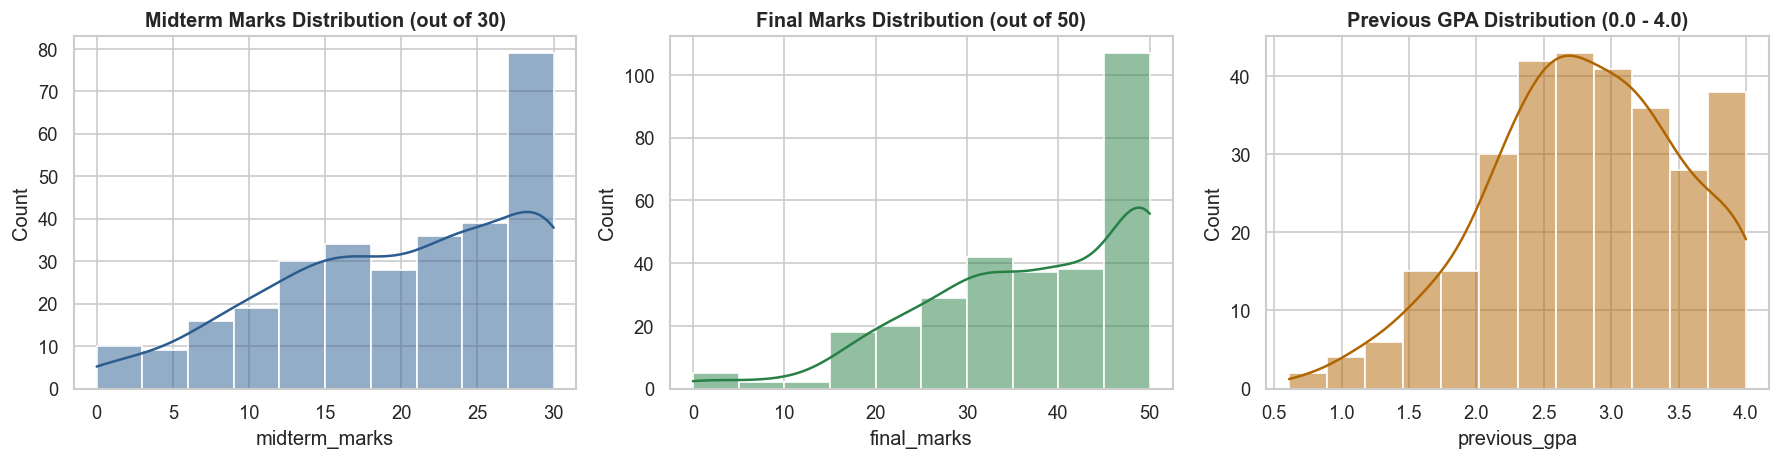

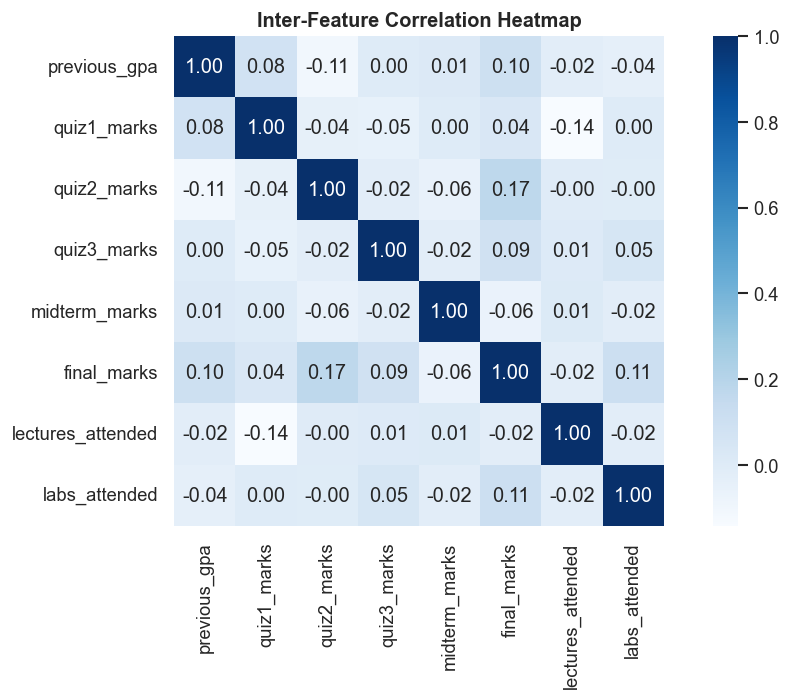

In [7]:
# Figure 1: Grade Distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df_raw['midterm_marks'], kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title('Midterm Marks Distribution (out of 30)', weight='bold')

sns.histplot(df_raw['final_marks'], kde=True, ax=axes[1], color='#278045')
axes[1].set_title('Final Marks Distribution (out of 50)', weight='bold')

sns.histplot(df_raw['previous_gpa'], kde=True, ax=axes[2], color='#b06500')
axes[2].set_title('Previous GPA Distribution (0.0 - 4.0)', weight='bold')
plt.tight_layout()
plt.show()

# Figure 2: Correlation Heatmap
plt.figure(figsize=(9, 6))
corr_cols = ['previous_gpa', 'quiz1_marks', 'quiz2_marks', 'quiz3_marks', 'midterm_marks', 'final_marks', 'lectures_attended', 'labs_attended']
sns.heatmap(df_raw[corr_cols].corr(), annot=True, fmt='.2f', cmap='Blues', square=True)
plt.title('Inter-Feature Correlation Heatmap', weight='bold', fontsize=12)
plt.tight_layout()
plt.show()

### Phase 3: Data Cleaning, Feature Engineering & Relational Normalization
- Drop 100% missing `assignments_submitted` and redundant constant `total_assignments`.
- Standardize text casing and decompose `name` into `first_name` and `last_name`.
- Engineer metrics: attendance percentages, attendance tiers, 100-pt composite score, letter grades, and rule-based dropout risk.
- Normalize into 3 relational entities: `students`, `attendance_records`, and `academic_assessments`.

In [8]:
df_clean = df_raw.copy()

# 1. Drop 100% missing assignments_submitted and constant total_assignments
df_clean = df_clean.drop(columns=['assignments_submitted', 'total_assignments'])

# 2. String standardization & attribute decomposition
df_clean['name'] = df_clean['name'].str.strip().str.title()
name_parts = df_clean['name'].str.split(' ', n=1, expand=True)
df_clean['first_name'] = name_parts[0]
df_clean['last_name'] = name_parts[1].fillna('')
df_clean['gender'] = df_clean['gender'].str.strip().str.capitalize()

# 3. Attendance metrics & tiers
df_clean['lecture_attendance_pct'] = (df_clean['lectures_attended'] / 12 * 100).round(2)
df_clean['lab_attendance_pct'] = (df_clean['labs_attended'] / 6 * 100).round(2)
df_clean['overall_attendance_pct'] = ((df_clean['lectures_attended'] + df_clean['labs_attended']) / 18 * 100).round(2)

def classify_attendance_tier(pct):
    if pct >= 80.0: return 'Excellent'
    elif pct >= 60.0: return 'Satisfactory'
    elif pct >= 40.0: return 'Irregular'
    else: return 'Critical'

df_clean['attendance_tier'] = df_clean['overall_attendance_pct'].apply(classify_attendance_tier)

# 4. Standardized composite score (100-pt scale)
quiz_tot = df_clean['quiz1_marks'] + df_clean['quiz2_marks'] + df_clean['quiz3_marks']
df_clean['avg_quiz_score'] = (quiz_tot / 3).round(2)
quiz_w = (quiz_tot / 30.0) * 20.0
df_clean['composite_score'] = (quiz_w + df_clean['midterm_marks'] + df_clean['final_marks']).round(2)

# 5. Letter grades & Academic standing
def assign_letter_grade(score):
    if score >= 85.0: return 'A'
    elif score >= 75.0: return 'B'
    elif score >= 65.0: return 'C'
    elif score >= 50.0: return 'D'
    else: return 'F'

df_clean['letter_grade'] = df_clean['composite_score'].apply(assign_letter_grade)

def assign_standing(row):
    if row['composite_score'] >= 85.0 and row['overall_attendance_pct'] >= 80.0:
        return "Dean's Honor List"
    elif row['composite_score'] >= 60.0:
        return 'Good Standing'
    elif row['composite_score'] >= 50.0:
        return 'Academic Warning'
    else:
        return 'Academic Probation'

df_clean['academic_standing'] = df_clean.apply(assign_standing, axis=1)

# 6. Rule-based dropout risk definition
def assign_dropout_risk(row):
    if row['overall_attendance_pct'] < 40.0 or row['composite_score'] < 45.0 or row['previous_gpa'] < 1.8:
        return 'High Risk'
    elif row['overall_attendance_pct'] < 60.0 or row['composite_score'] < 60.0 or row['previous_gpa'] < 2.5:
        return 'Medium Risk'
    else:
        return 'Low Risk'

df_clean['dropout_risk'] = df_clean.apply(assign_dropout_risk, axis=1)

# Age group classification
df_clean['age_group'] = pd.cut(df_clean['age'], bins=[17, 19, 22, 26], labels=['18-19', '20-22', '23-25']).astype(str)

print('Feature engineering completed successfully!')

Feature engineering completed successfully!


#### 3.2 Splitting into 3 Normalized Relational Entities
Normalized schema: `students` (Parent), `attendance_records` (Child), `academic_assessments` (Child).

In [9]:
# Table 1: students
df_students = df_clean[['student_id', 'first_name', 'last_name', 'age', 'age_group', 'gender', 'previous_gpa']].copy()

# Table 2: attendance_records
df_attendance = df_clean[['student_id', 'total_lectures', 'lectures_attended', 'lecture_attendance_pct',
                          'total_lab_sessions', 'labs_attended', 'lab_attendance_pct',
                          'overall_attendance_pct', 'attendance_tier']].copy()
df_attendance.insert(0, 'attendance_id', range(1, len(df_attendance) + 1))

# Table 3: academic_assessments
df_assessments = df_clean[['student_id', 'quiz1_marks', 'quiz2_marks', 'quiz3_marks', 'avg_quiz_score',
                           'midterm_marks', 'final_marks', 'composite_score', 'letter_grade',
                           'academic_standing', 'dropout_risk']].copy()
df_assessments.insert(0, 'assessment_id', range(1, len(df_assessments) + 1))

print(f'1. students: {df_students.shape}')
print(f'2. attendance_records: {df_attendance.shape}')
print(f'3. academic_assessments: {df_assessments.shape}')

1. students: (300, 7)
2. attendance_records: (300, 10)
3. academic_assessments: (300, 12)


### Phase 4: Data Analysis & Business Insights
Answering 5 core analytical questions and deriving data-backed insights.

In [10]:
df_merged = df_assessments.merge(df_students, on='student_id').merge(df_attendance, on='student_id')

print('[Q1] Average Composite Score by Attendance Tier:')
q1 = df_merged.groupby('attendance_tier').agg(
    student_count=('student_id', 'count'),
    avg_composite_score=('composite_score', 'mean'),
    avg_midterm=('midterm_marks', 'mean'),
    avg_final=('final_marks', 'mean')
).round(2).sort_values('avg_composite_score', ascending=False)
print(q1)

print('\n[Q2] Demographic Breakdown of High Risk Students:')
q2_gender = df_merged.groupby('gender')['dropout_risk'].value_counts(normalize=True).unstack().round(3) * 100
print('Gender Proportions (%):\n', q2_gender)
q2_age = df_merged.groupby('age_group')['dropout_risk'].value_counts(normalize=True).unstack().round(3) * 100
print('\nAge Group Proportions (%):\n', q2_age)

print('\n[Q3] Dean\'s Honor List Cohort Count:')
deans_count = (df_merged['academic_standing'] == "Dean's Honor List").sum()
print(f'Total Honor Students: {deans_count} ({deans_count / len(df_merged) * 100:.2f}% of cohort)')

print('\n[Q4] Key Correlation Analysis:')
r_gpa_final = df_merged['previous_gpa'].corr(df_merged['final_marks'])
r_att_final = df_merged['overall_attendance_pct'].corr(df_merged['final_marks'])
print(f'  - Previous GPA vs Final Marks: r = {r_gpa_final:.3f}')
print(f'  - Overall Attendance vs Final Marks: r = {r_att_final:.3f}')

print('\n[Q5] Lab vs Lecture Attendance Impact:')
high_lab = df_merged[df_merged['lab_attendance_pct'] >= 80]['final_marks'].mean()
low_lab = df_merged[df_merged['lab_attendance_pct'] < 40]['final_marks'].mean()
high_lec = df_merged[df_merged['lecture_attendance_pct'] >= 80]['final_marks'].mean()
low_lec = df_merged[df_merged['lecture_attendance_pct'] < 40]['final_marks'].mean()
print(f'  - Lab >=80% Avg: {high_lab:.2f} | Lab <40% Avg: {low_lab:.2f} (Diff: {high_lab - low_lab:.2f})')
print(f'  - Lecture >=80% Avg: {high_lec:.2f} | Lecture <40% Avg: {low_lec:.2f} (Diff: {high_lec - low_lec:.2f})')

[Q1] Average Composite Score by Attendance Tier:
                 student_count  avg_composite_score  avg_midterm  avg_final
attendance_tier                                                            
Irregular                   65                71.64        22.29      37.12
Excellent                   37                71.34        18.72      40.55
Critical                   119                69.25        19.63      37.06
Satisfactory                79                68.15        19.15      36.58

[Q2] Demographic Breakdown of High Risk Students:
Gender Proportions (%):
 dropout_risk  High Risk  Low Risk  Medium Risk
gender                                        
Female             44.5      21.3         34.2
Male               55.2      17.2         27.6

Age Group Proportions (%):
 dropout_risk  High Risk  Low Risk  Medium Risk
age_group                                     
18-19              50.0      20.8         29.2
20-22              50.4      19.5         30.1
23-25         

#### 4.2 Analytical Visualizations

C:\Users\LOQ\AppData\Local\Temp\ipykernel_32304\2521637043.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_merged, x='attendance_tier', y='composite_score', order=tier_order, palette='Blues_r', ax=axes[0])


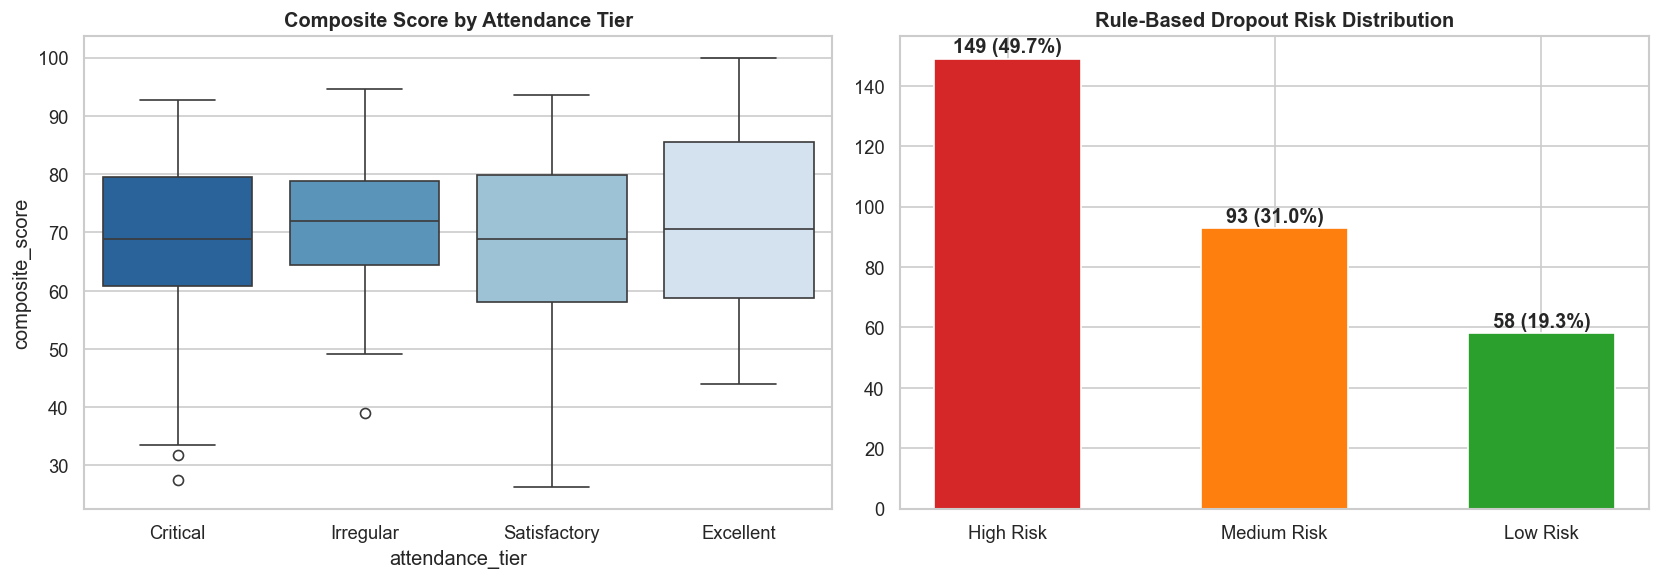

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Attendance Tier vs Composite Score Boxplot
tier_order = ['Critical', 'Irregular', 'Satisfactory', 'Excellent']
sns.boxplot(data=df_merged, x='attendance_tier', y='composite_score', order=tier_order, palette='Blues_r', ax=axes[0])
axes[0].set_title('Composite Score by Attendance Tier', weight='bold')

# Dropout Risk Proportions Bar Chart
risk_counts = df_merged['dropout_risk'].value_counts()
axes[1].bar(risk_counts.index, risk_counts.values, color=['#d62728', '#ff7f0e', '#2ca02c'], width=0.55)
axes[1].set_title('Rule-Based Dropout Risk Distribution', weight='bold')
for i, v in enumerate(risk_counts.values):
    axes[1].text(i, v + 2, f'{v} ({v/len(df_merged)*100:.1f}%)', ha='center', weight='bold')

plt.tight_layout()
plt.show()

### Phase 5 & 6: Relational Database Loading (SQLAlchemy + SQLite)
Creating SQLite database schema with PK, FK, and CHECK constraints and loading normalized DataFrames.

In [12]:
db_path = os.path.join('..', 'database', 'student_performance.db')
schema_path = os.path.join('..', 'database', 'schema_and_queries.sql')

# Create engine
engine = create_engine(f'sqlite:///{os.path.abspath(db_path)}', echo=False)

# Execute DDL statements
with open(schema_path, 'r', encoding='utf-8') as f:
    sql_script = f.read()

ddl_part = sql_script.split('-- PHASE 7:')[0]

raw_conn = sqlite3.connect(db_path)
raw_conn.execute('PRAGMA foreign_keys = ON;')
raw_conn.executescript(ddl_part)
raw_conn.commit()
raw_conn.close()

# Load DataFrames in dependency-safe order
df_students.to_sql('students', con=engine, if_exists='append', index=False)
df_attendance.to_sql('attendance_records', con=engine, if_exists='append', index=False)
df_assessments.to_sql('academic_assessments', con=engine, if_exists='append', index=False)

# Verify counts in SQLite
with engine.connect() as conn:
    print('SQLite Database Row Verification:')
    for tbl in ['students', 'attendance_records', 'academic_assessments']:
        cnt = conn.execute(text(f'SELECT COUNT(*) FROM {tbl}')).scalar()
        print(f'  - Table {tbl}: {cnt} rows')

SQLite Database Row Verification:
  - Table students: 300 rows
  - Table attendance_records: 300 rows
  - Table academic_assessments: 300 rows


### Phase 7: SQL Analytical Reporting
Executing multi-table SQL queries demonstrating JOINs, CASE expressions, window functions, and aggregations.

In [13]:
# Query 1: Performance & Risk Breakdown by Attendance Tier (JOIN, GROUP BY, CASE)
query1 = '''
SELECT
    att.attendance_tier,
    COUNT(s.student_id) AS total_students,
    ROUND(AVG(att.overall_attendance_pct), 2) AS avg_attendance_pct,
    ROUND(AVG(a.composite_score), 2) AS avg_composite_score,
    ROUND(AVG(a.final_marks), 2) AS avg_final_marks,
    SUM(CASE WHEN a.dropout_risk = 'High Risk' THEN 1 ELSE 0 END) AS high_risk_count
FROM attendance_records att
JOIN students s ON att.student_id = s.student_id
JOIN academic_assessments a ON att.student_id = a.student_id
GROUP BY att.attendance_tier
ORDER BY avg_composite_score DESC;
'''
print('--- Query 1: Attendance Tier Outcomes ---')
print(pd.read_sql(query1, con=engine))

# Query 2: Dean's Honor List Recognition Roster (Multi-table JOIN, WHERE, ORDER BY)
query2 = '''
SELECT
    s.student_id,
    s.first_name || ' ' || s.last_name AS full_name,
    s.gender,
    att.overall_attendance_pct,
    a.composite_score,
    a.letter_grade
FROM students s
JOIN academic_assessments a ON s.student_id = a.student_id
JOIN attendance_records att ON s.student_id = att.student_id
WHERE a.academic_standing = "Dean's Honor List"
ORDER BY a.composite_score DESC;
'''
print('\n--- Query 2: Dean\'s Honor List Recipients ---')
print(pd.read_sql(query2, con=engine))

# Query 3: Overall Top-5 Students (CTE + Window Function DENSE_RANK)
query3 = '''
WITH RankedStudents AS (
    SELECT
        s.student_id,
        s.first_name || ' ' || s.last_name AS student_name,
        a.composite_score,
        a.letter_grade,
        DENSE_RANK() OVER (ORDER BY a.composite_score DESC) as overall_rank
    FROM students s
    JOIN academic_assessments a ON s.student_id = a.student_id
)
SELECT * FROM RankedStudents WHERE overall_rank <= 5;
'''
print('\n--- Query 3: Top 5 Students by Composite Score ---')
print(pd.read_sql(query3, con=engine))

--- Query 1: Attendance Tier Outcomes ---
  attendance_tier  total_students  avg_attendance_pct  avg_composite_score  \
0       Irregular              65               49.83                71.64   
1       Excellent              37               87.99                71.34   
2        Critical             119               27.17                69.25   
3    Satisfactory              79               69.34                68.15   

   avg_final_marks  high_risk_count  
0            37.12                7  
1            40.55                8  
2            37.06              119  
3            36.58               15  

--- Query 2: Dean's Honor List Recipients ---
    student_id           full_name  gender  overall_attendance_pct  \
0          250    Angela Rodriguez  Female                   88.89   
1          280         Karen Frost  Female                   94.44   
2           71     Dr. Susan James    Male                   83.33   
3          148          Amy George  Female        

### Conclusion
The entire ETL, EDA, Transformation, 3-Table Relational Database Loading, and SQL Reporting pipeline runs end-to-end with complete referential integrity and verified data validity.